# Clase 41 · Agrupamiento: k-medias y jerárquico · sobre CAMMESA
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026 · Grupo 6**

Pregunta: ¿hay **grupos de agentes del mercado eléctrico que se comportan parecido**, cuántos, y cómo son? Nadie dice qué es parecido ni cuántos grupos hay: no hay columna a predecir, no hay prueba, no hay exactitud. Es la primera clase **sin etiquetas**.

Tres partes: **1 · los datos** (una fila por agente, con seis números que resumen su historia, escalados), **2 · el modelo** (k-medias: cuántos grupos, qué es cada uno; el jerárquico como contraste), **3 · usarlo** (a qué grupo va un agente nuevo, y la app Streamlit).

## 1 · Los datos

El CSV de CAMMESA tiene una fila por agente y por mes. Para agrupar **agentes** hace falta una fila por agente, así que cada serie (agente + tarifa) con al menos 24 meses se resume en **seis números**:

- `log_tamano`: log₁₀ de la demanda media (3 ≈ 1 000 MWh por mes; 4 ≈ 10 000).
- `estacionalidad`: log₂ de verano / invierno (+1 es el doble en verano, −1 el doble en invierno, 0 parejo).
- `volatilidad`: la variación mensual típica (la mediana del cambio absoluto).
- `tendencia_anual`: cuánto crece o cae por año (pendiente del log₁₀).
- `frac_caidas`: en qué fracción de los meses cayó más de 15 % (el objetivo de las clases de clasificación, resumido).
- `cv`: desvío / media, cuánto varía en general.

La tarifa y el tipo de agente (distribuidor o gran usuario) **no entran**: se guardan aparte para comparar al final qué encontró el algoritmo sin verlos.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
demanda = demanda.sort_values(["serie", "periodo"])

def perfil(g):
    """Seis números que resumen cómo se comporta la demanda de una serie a lo largo de su historia."""
    s = g.set_index("periodo")["demanda_MWh"]
    if len(s) < 24 or (s <= 0).mean() > 0.1:
        return None                                                            # muy corta, o con muchos meses en cero
    pos = s[s > 0]
    cambio = (s / s.shift(1) - 1)[s.shift(1) > 0].clip(-1, 3)
    mes = pos.index.month
    verano, invierno = pos[np.isin(mes, [12, 1, 2])].mean(), pos[np.isin(mes, [6, 7, 8])].mean()
    anios = np.array([(p - pos.index[0]).n for p in pos.index]) / 12
    return pd.Series({"log_tamano": np.log10(pos.mean()), "estacionalidad": np.log2(verano / invierno),
                      "volatilidad": cambio.abs().median(), "tendencia_anual": np.polyfit(anios, np.log10(pos.to_numpy()), 1)[0],
                      "frac_caidas": (cambio < -0.15).mean(), "cv": pos.std() / pos.mean()})
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    perfiles = demanda.groupby("serie").apply(perfil).dropna()
COLUMNAS = ["log_tamano", "estacionalidad", "volatilidad", "tendencia_anual", "frac_caidas", "cv"]
etiquetas = demanda.groupby("serie")[["categoria_tarifa", "categoria_demanda"]].first().loc[perfiles.index]
print(f"{demanda['serie'].nunique()} series en el CSV · {len(perfiles)} con 24 meses o más · tarifas: {etiquetas['categoria_tarifa'].value_counts().to_dict()}")
perfiles[COLUMNAS].describe().round(3).T

1768 series en el CSV · 868 con 24 meses o más · tarifas: {'Industrial/Comercial Grande': 526, 'Residencial': 267, 'Comercial': 75}


,count,mean,std,min,25%,50%,75%,max
log_tamano,868.0,3.219,0.921,-0.740,2.779,3.212,3.732,5.888
estacionalidad,868.0,0.017,0.406,-2.240,-0.194,-0.005,0.198,2.577
volatilidad,868.0,0.107,0.086,0.000,0.058,0.086,0.125,0.988
tendencia_anual,868.0,0.013,0.157,-1.033,-0.032,-0.002,0.047,1.168
frac_caidas,868.0,0.132,0.103,0.000,0.054,0.114,0.189,0.533
cv,868.0,0.261,0.225,0.029,0.125,0.195,0.316,1.887


### Las seis columnas, una por una

Histogramas (recortados al 1–99 % para el dibujo). Dos cosas para ver: las escalas son distintas (el tamaño va de −0,7 a 5,9; la volatilidad, de 0 a 1), y tres columnas (volatilidad, frecuencia de caídas y variabilidad) miden casi lo mismo: qué tan estable es el agente.

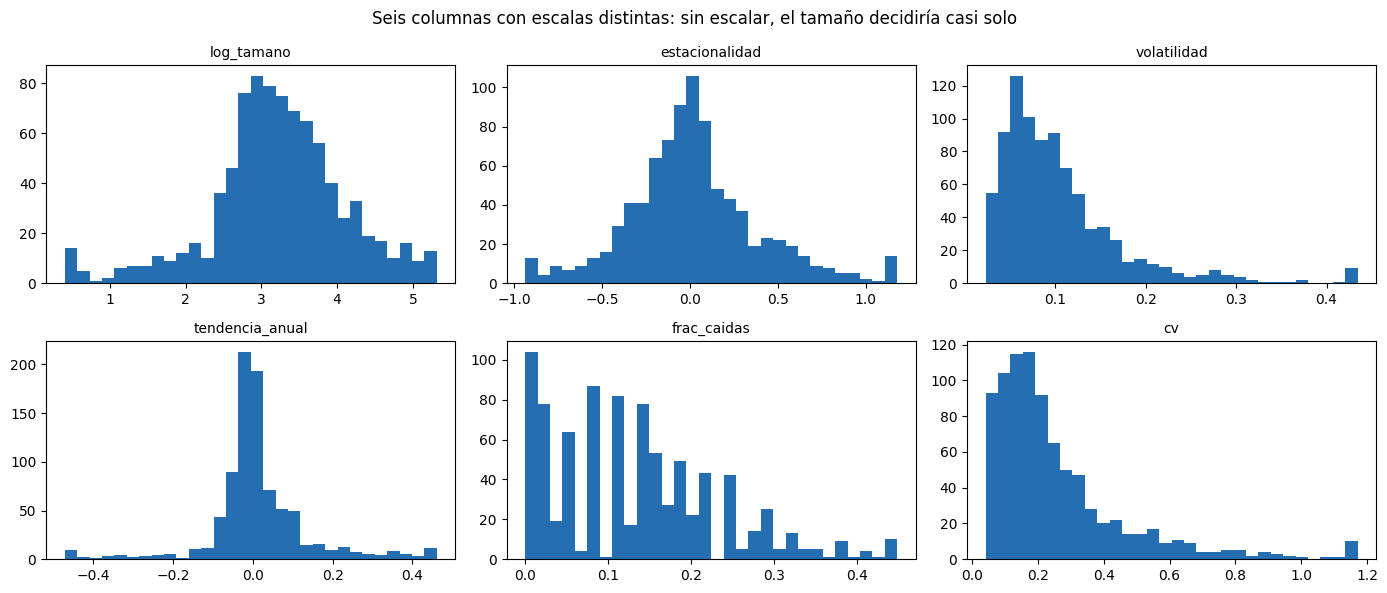

Correlación entre las tres columnas de estabilidad: {'volatilidad': {'volatilidad': 1.0, 'frac_caidas': 0.77, 'cv': 0.62}, 'frac_caidas': {'volatilidad': 0.77, 'frac_caidas': 1.0, 'cv': 0.58}, 'cv': {'volatilidad': 0.62, 'frac_caidas': 0.58, 'cv': 1.0}}


In [2]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 6)); ejes = ejes.ravel()
for ax, col in zip(ejes, COLUMNAS):
    v = perfiles[col]; ax.hist(v.clip(*v.quantile([0.01, 0.99])), bins=30, color="#0055a5", alpha=0.85); ax.set_title(col, fontsize=10)
fig.suptitle("Seis columnas con escalas distintas: sin escalar, el tamaño decidiría casi solo")
plt.tight_layout(); plt.show()
print("Correlación entre las tres columnas de estabilidad:", perfiles[["volatilidad", "frac_caidas", "cv"]].corr().round(2).to_dict())

### Escalar

Cada columna queda con media 0 y desvío 1, para que el tamaño (desvío 0,92) pese lo mismo que la volatilidad (desvío 0,09). Sin esto, la distancia entre dos agentes sería casi solo la diferencia de tamaño. No hay faltantes (las series incompletas ya quedaron afuera), así que no hace falta imputar. `Z` es lo que ve el algoritmo.

In [3]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler().fit(perfiles[COLUMNAS])
Z = escalador.transform(perfiles[COLUMNAS])
print("Desvío de cada columna antes de escalar:", {c: round(float(perfiles[c].std()), 3) for c in COLUMNAS})
print(f"Z: {Z.shape[0]} series × {Z.shape[1]} columnas · media de cada columna ≈ {Z.mean(axis=0).round(2).tolist()} · desvío ≈ {Z.std(axis=0).round(2).tolist()}")

Desvío de cada columna antes de escalar: {'log_tamano': 0.921, 'estacionalidad': 0.406, 'volatilidad': 0.086, 'tendencia_anual': 0.157, 'frac_caidas': 0.103, 'cv': 0.225}
Z: 868 series × 6 columnas · media de cada columna ≈ [0.0, -0.0, -0.0, 0.0, 0.0, 0.0] · desvío ≈ [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 2 · El modelo

### k-medias: qué hace

Se eligen k puntos (centroides). Cada agente va al centroide más cercano; cada centroide se mueve a la media de su grupo; se repite hasta que nada cambia. La **inercia** es la suma de distancias al cuadrado de cada agente a su centroide: lo que el algoritmo minimiza. Como depende de dónde arrancan los centroides, la biblioteca corre `n_init` veces y se queda con la de menor inercia.

Primero, con dos columnas para verlo: tamaño y volatilidad, tres grupos.

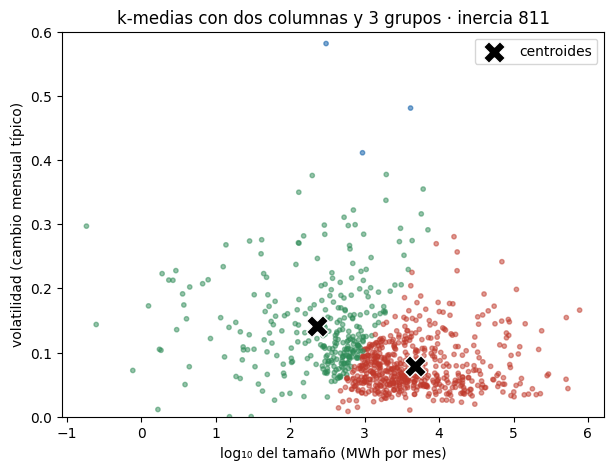

Con dos columnas se ve lo que hace: cada agente con el centroide más cercano, y los centroides en el medio de su grupo. Los límites entre grupos son rectos.


In [4]:
from sklearn.cluster import KMeans

i1, i2 = COLUMNAS.index("log_tamano"), COLUMNAS.index("volatilidad")
dos = Z[:, [i1, i2]]
km2 = KMeans(n_clusters=3, n_init=10, random_state=2026).fit(dos)
COLORES = ["#0055a5", "#c0392b", "#2e8b57"]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(perfiles["log_tamano"], perfiles["volatilidad"], c=[COLORES[g] for g in km2.labels_], s=10, alpha=0.5)
centros2 = escalador.mean_[[i1, i2]] + km2.cluster_centers_ * escalador.scale_[[i1, i2]]      # los centroides, devueltos a las unidades originales
ax.scatter(centros2[:, 0], centros2[:, 1], marker="X", s=250, c="black", edgecolor="white", zorder=5, label="centroides")
ax.set_xlabel("log₁₀ del tamaño (MWh por mes)"); ax.set_ylabel("volatilidad (cambio mensual típico)"); ax.set_ylim(0, 0.6); ax.legend()
ax.set_title(f"k-medias con dos columnas y 3 grupos · inercia {km2.inertia_:.0f}")
plt.show()
print("Con dos columnas se ve lo que hace: cada agente con el centroide más cercano, y los centroides en el medio de su grupo. Los límites entre grupos son rectos.")

### Cuántos grupos: el codo y la silueta

Ahora con las seis columnas. Para k de 2 a 8: la **inercia** (baja siempre; se busca un codo) y la **silueta**: para cada agente, (b − a)/max(a, b), con a la distancia media a los de su grupo y b a los del grupo más cercano; cerca de 1 bien adentro, cerca de 0 en el límite, negativo quizá en el grupo equivocado. El promedio tiene un máximo.

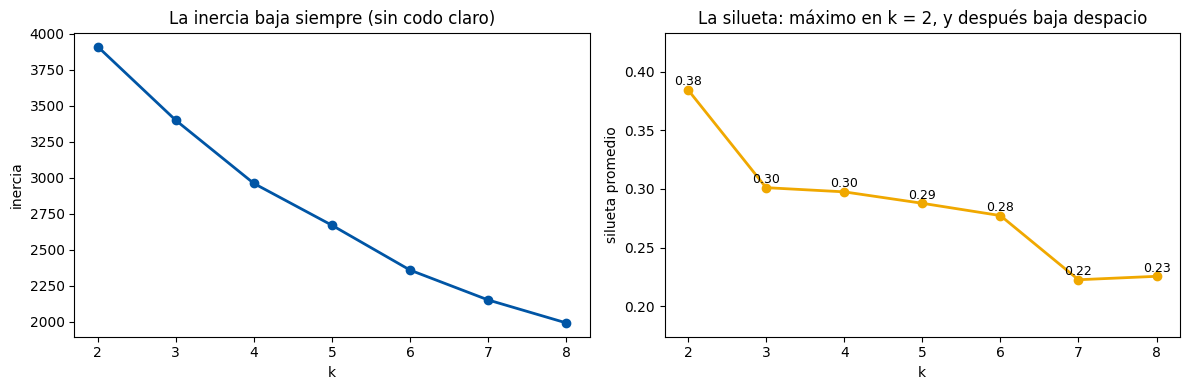

Silueta por k: {2: 0.384, 3: 0.301, 4: 0.297, 5: 0.288, 6: 0.277, 7: 0.223, 8: 0.226}
Tamaño del grupo más chico por k: {2: 231, 3: 45, 4: 25, 5: 18, 6: 14, 7: 9, 8: 9}


In [5]:
from sklearn.metrics import silhouette_score, silhouette_samples

ks = range(2, 9)
modelos = {k: KMeans(n_clusters=k, n_init=10, random_state=2026).fit(Z) for k in ks}
inercias = [modelos[k].inertia_ for k in ks]; siluetas = [silhouette_score(Z, modelos[k].labels_) for k in ks]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.plot(list(ks), inercias, marker="o", color="#0055a5", lw=2); a.set_xlabel("k"); a.set_ylabel("inercia"); a.set_title("La inercia baja siempre (sin codo claro)")
b.plot(list(ks), siluetas, marker="o", color="#f0a800", lw=2); b.set_xlabel("k"); b.set_ylabel("silueta promedio"); b.set_title(f"La silueta: máximo en k = {list(ks)[int(np.argmax(siluetas))]}, y después baja despacio")
for k, s in zip(ks, siluetas): b.text(k, s + 0.004, f"{s:.2f}", ha="center", fontsize=9)
b.margins(y=0.3); plt.tight_layout(); plt.show()
print("Silueta por k:", {k: round(float(s), 3) for k, s in zip(ks, siluetas)})
print("Tamaño del grupo más chico por k:", {k: int(np.bincount(modelos[k].labels_).min()) for k in ks})

La silueta es máxima con k = 2 (~0,38) y con k = 3 da ~0,30: hay estructura, bastante más que en los socios del gimnasio (0,17 a 0,21), pero no son islas. Con k = 2 los grupos son «estables» contra «no estables»; con k = 3 los no estables se dividen en dos comportamientos distintos que vale la pena separar. Con k grande aparecen grupos de un puñado de agentes extremos. Se elige **k = 3** porque los tres grupos se leen (sigue abajo), sabiendo que k = 2 da más.

### El modelo elegido: k = 3

Tres grupos sobre las seis columnas. Los centroides se devuelven a las unidades originales para leerlos (y se traducen: MWh por mes, verano / invierno, crecimiento por año), y se cruzan con la tarifa y el tipo de agente, que el algoritmo no vio.

In [6]:
km = modelos[3]
grupos = km.labels_
centros = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=COLUMNAS, index=[f"grupo {j}" for j in range(3)])
legibles = pd.DataFrame({"series": np.bincount(grupos), "demanda media (MWh/mes)": (10 ** centros["log_tamano"]).round(0).values,
                         "verano / invierno": (2 ** centros["estacionalidad"]).round(2).values, "volatilidad": centros["volatilidad"].round(3).values,
                         "crecimiento anual (%)": ((10 ** centros["tendencia_anual"] - 1) * 100).round(1).values,
                         "meses con caída fuerte (%)": (centros["frac_caidas"] * 100).round(1).values, "cv": centros["cv"].round(2).values}, index=centros.index)
print("Los centroides, en las unidades originales:"); display(legibles)
print("Los grupos contra la tarifa y el tipo de agente (que no entraron):")
g_ = pd.Series(grupos, index=perfiles.index, name="grupo")
display(pd.concat([pd.crosstab(g_, etiquetas["categoria_tarifa"]), pd.crosstab(g_, etiquetas["categoria_demanda"])], axis=1))

Los centroides, en las unidades originales:


,series,demanda media (MWh/mes),verano / invierno,volatilidad,crecimiento anual (%),meses con caída fuerte (%),cv
grupo 0,539,3510.0,1.04,0.070,-0.9,7.5,0.15
grupo 1,45,677.0,1.67,0.307,-16.6,32.6,0.84
grupo 2,284,459.0,0.90,0.145,14.9,21.0,0.38


Los grupos contra la tarifa y el tipo de agente (que no entraron):


,Comercial,Industrial/Comercial Grande,Residencial,Distribuidor,Gran Usuario
grupo,,,,,
0,69,364,106,219,320
1,1,30,14,23,22
2,5,132,147,165,119


### Qué es cada grupo

El centroide de cada grupo, columna por columna, en unidades escaladas: una barra hacia arriba es «más que el agente promedio», hacia abajo «menos». Los nombres se ponen mirando los centroides: el de mayor tamaño, el de mayor estacionalidad, y el que queda.

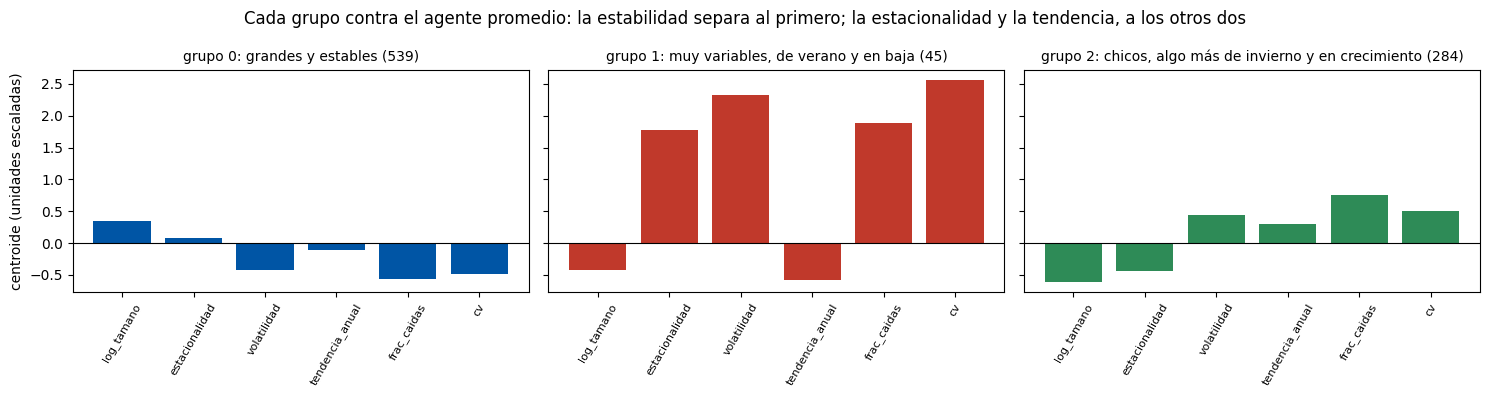

grupo 0: grandes y estables
grupo 1: muy variables, de verano y en baja
grupo 2: chicos, algo más de invierno y en crecimiento


In [7]:
j_grande = int(np.argmax(centros["log_tamano"].to_numpy()))
resto = [j for j in range(3) if j != j_grande]
j_verano = max(resto, key=lambda j: centros["estacionalidad"].iloc[j])
j_otro = [j for j in resto if j != j_verano][0]
nombres = {j_grande: "grandes y estables", j_verano: "muy variables, de verano y en baja", j_otro: "chicos, algo más de invierno y en crecimiento"}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for j, ax in enumerate(ejes):
    ax.bar(COLUMNAS, km.cluster_centers_[j], color=COLORES[j]); ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"grupo {j}: {nombres[j]} ({np.bincount(grupos)[j]})", fontsize=10); ax.tick_params(axis="x", rotation=60, labelsize=8)
ejes[0].set_ylabel("centroide (unidades escaladas)")
fig.suptitle("Cada grupo contra el agente promedio: la estabilidad separa al primero; la estacionalidad y la tendencia, a los otros dos")
plt.tight_layout(); plt.show()
for j in range(3): print(f"grupo {j}: {nombres[j]}")

- **Grandes y estables**: el grupo más grande. Agentes de varios miles de MWh por mes, casi sin estacionalidad, que caen fuerte muy pocas veces.
- **Muy variables, de verano y en baja**: un grupo chico. En verano consumen dos tercios más que en invierno, caen fuerte uno de cada tres meses y, en conjunto, vienen bajando.
- **Chicos, algo más de invierno y en crecimiento**: agentes de unos cientos de MWh, con un leve pico en invierno y que crecen año a año.

Los grupos **cruzan** las tarifas y los tipos de agente: lo que encontró el algoritmo no es la tarifa con otro nombre.

### Los grupos, vistos en dos columnas, y en el tiempo

Las 868 series con el color de su grupo (calculado con las seis columnas), sobre dos pares de columnas. Y lo que los seis números resumen: la demanda de cada serie dividida por su propia media, mes a mes, con la mediana de cada grupo.

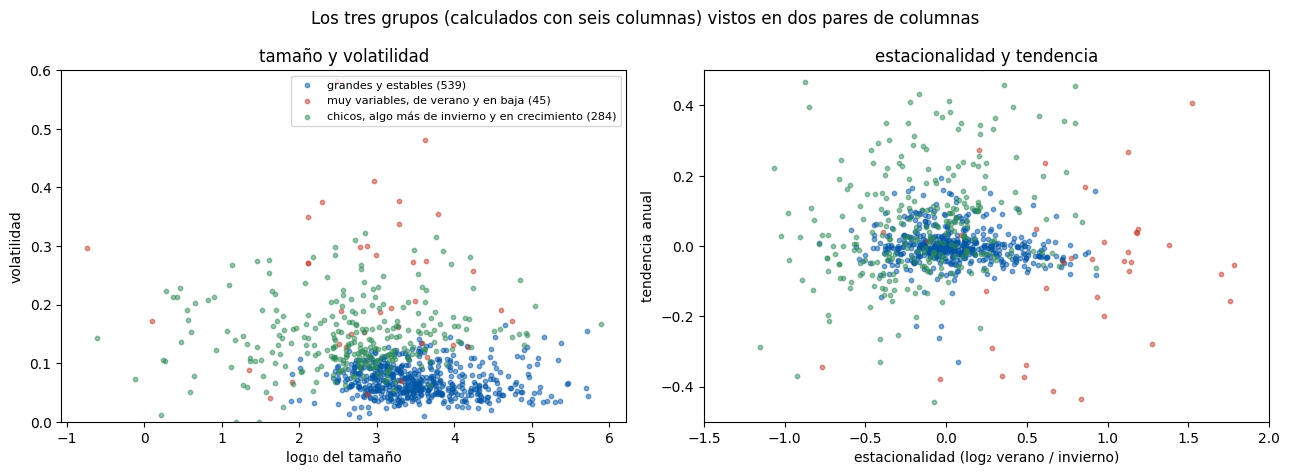

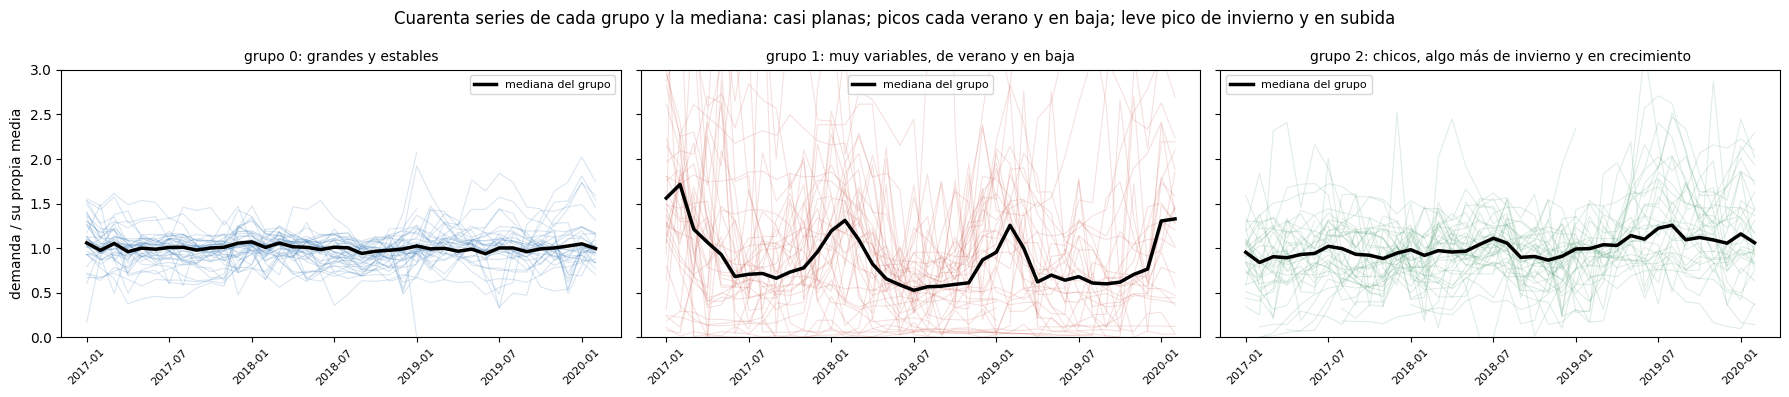

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.8))
for j in range(3):
    sel = grupos == j
    a.scatter(perfiles.loc[sel, "log_tamano"], perfiles.loc[sel, "volatilidad"], s=10, alpha=0.5, color=COLORES[j], label=f"{nombres[j]} ({sel.sum()})")
    b.scatter(perfiles.loc[sel, "estacionalidad"], perfiles.loc[sel, "tendencia_anual"], s=10, alpha=0.5, color=COLORES[j])
a.set_xlabel("log₁₀ del tamaño"); a.set_ylabel("volatilidad"); a.set_ylim(0, 0.6); a.legend(fontsize=8); a.set_title("tamaño y volatilidad")
b.set_xlabel("estacionalidad (log₂ verano / invierno)"); b.set_ylabel("tendencia anual"); b.set_xlim(-1.5, 2); b.set_ylim(-0.5, 0.5); b.set_title("estacionalidad y tendencia")
fig.suptitle("Los tres grupos (calculados con seis columnas) vistos en dos pares de columnas")
plt.tight_layout(); plt.show()

curvas = demanda[demanda["serie"].isin(perfiles.index)].pivot_table(index="serie", columns="periodo", values="demanda_MWh")
curvas = curvas.div(curvas.mean(axis=1), axis=0)
fig, ejes = plt.subplots(1, 3, figsize=(18, 4), sharey=True); x = np.arange(curvas.shape[1])
for ax, j in zip(ejes, range(3)):
    sub = curvas.loc[perfiles.index[grupos == j]]
    for _, fila_c in sub.sample(min(40, len(sub)), random_state=2026).iterrows(): ax.plot(x, fila_c.values, color=COLORES[j], alpha=0.15, lw=0.8)
    ax.plot(x, sub.median().values, color="black", lw=2.5, label="mediana del grupo")
    ax.set_xticks(x[::6]); ax.set_xticklabels([str(p) for p in curvas.columns][::6], rotation=45, fontsize=8); ax.set_ylim(0, 3)
    ax.set_title(f"grupo {j}: {nombres[j]}", fontsize=10); ax.legend(fontsize=8)
ejes[0].set_ylabel("demanda / su propia media")
fig.suptitle("Cuarenta series de cada grupo y la mediana: casi planas; picos cada verano y en baja; leve pico de invierno y en subida")
plt.tight_layout(); plt.show()

### El diagrama de silueta

Un coeficiente por serie, ordenados por grupo. Cada forma es un grupo: su altura, cuántas series; su ancho, qué tan adentro están. La línea roja es el promedio.

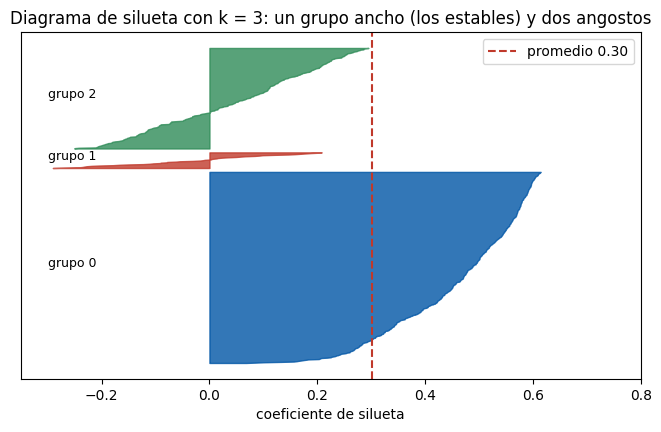

Silueta media por grupo: grandes y estables 0.46 · muy variables, de verano y en baja -0.03 · chicos, algo más de invierno y en crecimiento 0.05
Series con coeficiente negativo (más cerca de otro grupo que del suyo): 126 de 868


In [9]:
coef = silhouette_samples(Z, grupos)
fig, ax = plt.subplots(figsize=(8, 4.5)); y0 = 10
for j in range(3):
    v = np.sort(coef[grupos == j]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORES[j], alpha=0.8); ax.text(-0.3, y0 + len(v) / 2, f"grupo {j}", fontsize=9); y0 += len(v) + 10
ax.axvline(coef.mean(), color="#c0392b", ls="--", label=f"promedio {coef.mean():.2f}"); ax.set_xlim(-0.35, 0.8); ax.set_yticks([]); ax.set_xlabel("coeficiente de silueta"); ax.legend()
ax.set_title("Diagrama de silueta con k = 3: un grupo ancho (los estables) y dos angostos")
plt.show()
print(f"Silueta media por grupo: " + " · ".join(f"{nombres[j]} {coef[grupos == j].mean():.2f}" for j in range(3)))
print(f"Series con coeficiente negativo (más cerca de otro grupo que del suyo): {int((coef < 0).sum())} de {len(Z)}")

Acá está el matiz: el grupo de los grandes y estables está bien definido (silueta media ~0,46), pero los otros dos rondan el cero. Son agentes que se parecen más en «no ser estables» que entre sí: el centroide los describe en promedio, no uno por uno.

### El jerárquico, como contraste

El **aglomerativo** no mueve centroides: cada serie empieza sola, y se fusionan de a dos las más cercanas (con Ward: las que menos aumentan la varianza) hasta que quedan tres. Deja un **dendrograma**: la altura de cada unión es la distancia a la que se fusionaron; se corta donde la rama vertical es más larga. Con 868 no se lee; con 30 series al azar, sí. Y se compara con los grupos de k-medias.

Ward: tamaños [74, 338, 456] · silueta 0.178 (k-medias: 0.301) · coincidencia con k-medias (Rand ajustado, 1 = igual, 0 = azar): 0.25
Ward contra k-medias:


k-medias,0,1,2
Ward,,,
0,0,16,58
1,336,0,2
2,203,29,224


Ward arma un grupo que es casi todo de estables, pero reparte al resto de los estables con los chicos de invierno: el núcleo estable se repite, cómo se parte lo demás depende del camino.


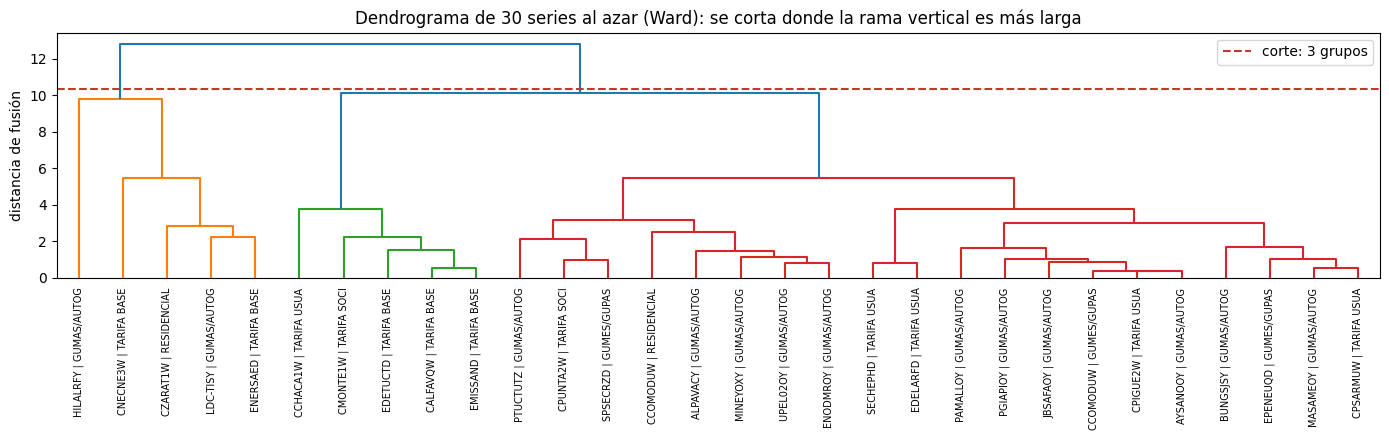

In [10]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

ward = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(Z)
print(f"Ward: tamaños {np.bincount(ward.labels_).tolist()} · silueta {silhouette_score(Z, ward.labels_):.3f} (k-medias: {silhouette_score(Z, grupos):.3f}) · coincidencia con k-medias (Rand ajustado, 1 = igual, 0 = azar): {adjusted_rand_score(grupos, ward.labels_):.2f}")
print("Ward contra k-medias:"); display(pd.crosstab(pd.Series(ward.labels_, name="Ward"), pd.Series(grupos, name="k-medias")))
print("Ward arma un grupo que es casi todo de estables, pero reparte al resto de los estables con los chicos de invierno: el núcleo estable se repite, cómo se parte lo demás depende del camino.")
muestra = np.random.default_rng(2026).choice(len(Z), 30, replace=False)
enlaces = linkage(Z[muestra], method="ward")
fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(enlaces, labels=[perfiles.index[i][:22] for i in muestra], leaf_font_size=7, leaf_rotation=90, color_threshold=enlaces[-2, 2], ax=ax)
ax.axhline(enlaces[-2, 2] * 1.02, color="#c0392b", ls="--", label="corte: 3 grupos"); ax.set_ylabel("distancia de fusión"); ax.legend()
ax.set_title("Dendrograma de 30 series al azar (Ward): se corta donde la rama vertical es más larga")
plt.tight_layout(); plt.show()

## 3 · Usarlo

### Un agente nuevo

Se arma la fila con su perfil, se escala con lo aprendido, `predict` dice el grupo (el centroide más cercano) y `transform` la distancia a cada centroide. Un comercio de unos 800 MWh por mes, que consume 40 % más en verano, con variaciones mensuales de ~12 %, que crece 3 % por año y cae fuerte uno de cada seis meses.

Grupo: 0 (grandes y estables)
Distancia a cada centroide: {'grandes y estables': 1.72, 'muy variables, de verano y en baja': 3.83, 'chicos, algo más de invierno y en crecimiento': 1.81}


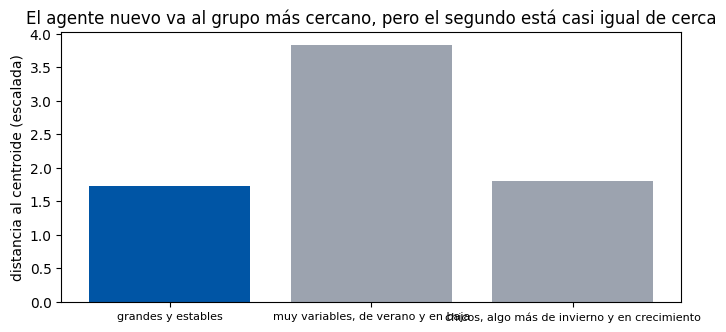

In [11]:
nuevo = pd.DataFrame([{"log_tamano": np.log10(800), "estacionalidad": np.log2(1.4), "volatilidad": 0.12, "tendencia_anual": np.log10(1.03), "frac_caidas": 1 / 6, "cv": 0.25}])[COLUMNAS]
z_nuevo = escalador.transform(nuevo)
grupo_nuevo = int(km.predict(z_nuevo)[0]); dist = km.transform(z_nuevo)[0]
print(f"Grupo: {grupo_nuevo} ({nombres[grupo_nuevo]})")
print("Distancia a cada centroide:", {nombres[j]: round(float(d), 2) for j, d in enumerate(dist)})
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([nombres[j] for j in range(3)], dist, color=[COLORES[j] if j == grupo_nuevo else "#9ca3af" for j in range(3)]); ax.set_ylabel("distancia al centroide (escalada)"); ax.tick_params(axis="x", labelsize=8)
ax.set_title("El agente nuevo va al grupo más cercano, pero el segundo está casi igual de cerca")
plt.show()

### Guardar el agrupamiento

Los dos pasos (escalar, k-medias) en un `Pipeline`, con los nombres de los grupos, los centroides y los perfiles de las 868 series (para que la app los dibuje sin volver a leer el CSV), en un solo archivo. La app lo carga.

In [12]:
import joblib
from sklearn.pipeline import Pipeline

agrupamiento = Pipeline([("escalar", StandardScaler()), ("kmedias", KMeans(n_clusters=3, n_init=10, random_state=2026))]).fit(perfiles[COLUMNAS])
assert (agrupamiento.predict(perfiles[COLUMNAS]) == grupos).all()             # los mismos grupos que arriba
joblib.dump({"modelo": agrupamiento, "nombres": nombres, "columnas": COLUMNAS, "centros": legibles, "perfiles": perfiles[COLUMNAS]}, "agrupamiento_cammesa_41.joblib")
print("Guardado: agrupamiento_cammesa_41.joblib · el agente nuevo por el pipeline:", nombres[int(agrupamiento.predict(nuevo)[0])])

Guardado: agrupamiento_cammesa_41.joblib · el agente nuevo por el pipeline: grandes y estables


### La aplicación Streamlit, desde el cuaderno

La celda siguiente escribe el archivo `app_cammesa_41.py` (seis controles con el perfil del agente en unidades que se entienden, el grupo, las distancias y dónde cae entre las 868 series). La de después lo abre.

In [13]:
%%writefile app_cammesa_41.py
# Clase 41 sobre CAMMESA · Agrupamiento · aplicación Streamlit
# Carga el agrupamiento guardado por el cuaderno (escalar → k-medias con 3 grupos) y ubica a un agente nuevo.
# Para abrirla:  streamlit run app_cammesa_41.py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="¿A qué grupo de agentes se parece?", layout="centered")
st.title("¿A qué grupo de agentes se parece?")
st.caption("k-medias con 3 grupos sobre el perfil de 868 series de demanda-ltimos-aos.csv (CAMMESA, clase 41). La tarifa y el tipo de agente no entran.")

guardado = joblib.load("agrupamiento_cammesa_41.joblib")
modelo, nombres, COLUMNAS, perfiles = guardado["modelo"], guardado["nombres"], guardado["columnas"], guardado["perfiles"]
grupos = modelo.predict(perfiles)
COLORES = ["#0055a5", "#c0392b", "#2e8b57"]

st.subheader("Perfil del agente")
c1, c2 = st.columns(2)
mwh = c1.number_input("Demanda media (MWh por mes)", 1.0, 800_000.0, 800.0, step=50.0)
ver_inv = c1.slider("Verano / invierno (1 = parejo)", 0.3, 3.0, 1.4, step=0.05)
volatilidad = c1.slider("Variación mensual típica (%)", 0.0, 60.0, 12.0, step=0.5)
crecimiento = c2.slider("Crecimiento por año (%)", -50.0, 50.0, 3.0, step=0.5)
caidas = c2.slider("Meses con caída de más de 15 % (%)", 0.0, 60.0, 17.0, step=1.0)
cv = c2.slider("Variabilidad (desvío / media)", 0.0, 2.0, 0.25, step=0.01)

fila = pd.DataFrame([{"log_tamano": np.log10(mwh), "estacionalidad": np.log2(ver_inv), "volatilidad": volatilidad / 100,
                      "tendencia_anual": np.log10(1 + crecimiento / 100), "frac_caidas": caidas / 100, "cv": cv}])[COLUMNAS]
grupo = int(modelo.predict(fila)[0])
distancias = modelo.transform(fila)[0]

st.subheader("Grupo")
st.metric("Se parece a los", nombres[grupo])
segundo = int(np.argsort(distancias)[1])
st.write("Distancia a cada centroide (en unidades escaladas): " + " · ".join(f"{nombres[j]} {d:.2f}" for j, d in enumerate(distancias))
         + f". El segundo más cercano es «{nombres[segundo]}»" + (": está entre dos grupos." if distancias[segundo] - distancias[grupo] < 0.5 else "."))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.bar([nombres[j] for j in range(3)], distancias, color=[COLORES[j] if j == grupo else "#9ca3af" for j in range(3)])
a.set_ylabel("distancia al centroide"); a.set_title("Más cerca del grupo coloreado"); a.tick_params(axis="x", labelsize=7, rotation=10)
for j in range(3):
    sel = grupos == j
    b.scatter(perfiles.loc[sel, "log_tamano"], perfiles.loc[sel, "volatilidad"], s=8, alpha=0.4, color=COLORES[j], label=nombres[j])
b.scatter([np.log10(mwh)], [volatilidad / 100], marker="*", s=350, color="black", edgecolor="white", zorder=5, label="este agente")
b.set_xlabel("log₁₀ del tamaño (MWh por mes)"); b.set_ylabel("volatilidad"); b.set_ylim(0, 0.6); b.set_title("Dónde cae entre las 868 series"); b.legend(fontsize=6)
plt.tight_layout(); st.pyplot(fig)

with st.expander("Ver los centroides de los tres grupos"):
    st.dataframe(guardado["centros"])

Writing app_cammesa_41.py


La celda que sigue abre la app. Mientras corre, la celda queda ocupada; para volver se interrumpe el kernel (■).

In [14]:
!streamlit run app_cammesa_41.py

^C


## Qué quedó

- Agrupar es encontrar agentes parecidos **sin etiquetas**: no hay respuesta correcta; se mide compacidad (inercia, silueta) y se mira si los grupos se leen.
- Para agrupar agentes **hubo que construir las filas**: una por serie, con seis números que resumen su historia. Esa elección decide qué es «parecido»; las curvas de cada grupo confirman que los resúmenes capturan algo real.
- k-medias: asignar y mover hasta converger; escalar antes es obligatorio (sin escalar, el tamaño decide casi solo); `n_init` corridas y gana la menor inercia.
- k no lo dice la inercia (baja siempre): se mira la silueta. Acá es 0,38 con 2 y 0,30 con 3, y se eligió k = 3 porque los grupos se leen: **grandes y estables**, **muy variables, de verano y en baja**, y **chicos, algo más de invierno y en crecimiento**. Solo el primero es nítido; los grupos cruzan las tarifas.
- El jerárquico fusiona de a dos y deja un dendrograma para cortar después; con Ward coincide poco con k-medias (Rand ajustado ~0,25): repite un núcleo de estables y parte distinto el resto.
- La app ubica a un agente nuevo: grupo, distancias y dónde cae entre las 868 series.